In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
X=np.array([
    [2,3],
    [3,4],
    [4,3],
    [10,11],
    [11,12],
    [12,11]
])

In [3]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X)
labels=kmeans.labels_
centroids = kmeans.cluster_centers_

In [4]:
print("Cluster labels: ")
print(labels)
print("\nCluster centers: ")
print(centroids)

Cluster labels: 
[0 0 0 1 1 1]

Cluster centers: 
[[ 3.          3.33333333]
 [11.         11.33333333]]


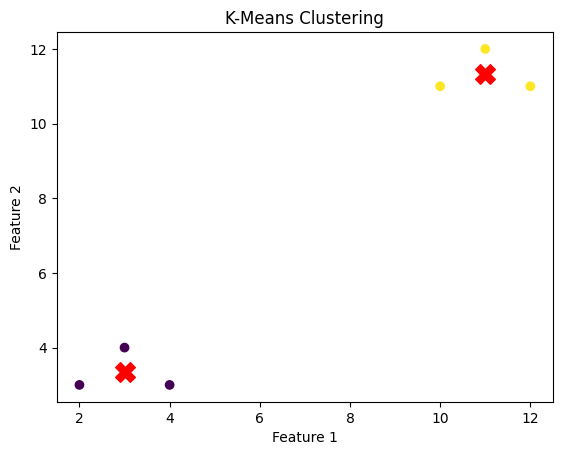

In [5]:
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
plt.scatter(centroids[:, 0], centroids[:, 1], color='red', marker='X', s=200)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.show()

# K-Medoid

In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
X=np.array([
    [2,3],
    [3,4],
    [4,3],
    [10,11],
    [11,12],
    [12,11]
])

In [8]:
k=2
medoid_indices=[0,3]

In [9]:
while True:
  distances = np.zeros((len(X), k))
  for i in range(len(X)):
    for j in range(k):
      distances[i, j] = np.linalg.norm(X[i] - X[medoid_indices[j]])
  labels = np.argmin(distances, axis=1)
  new_medoid_indices = []
  for cluster_id in range(k):
    cluster_points_indices = np.where(labels == cluster_id)[0]

    if len(cluster_points_indices) == 0:
      new_medoid_indices.append(medoid_indices[cluster_id])
      continue
    min_cost = float('inf')
    best_new_medoid_idx_in_cluster = -1

    for candidate_medoid_idx in cluster_points_indices:
      current_point_cost = 0
      for other_point_idx in cluster_points_indices:
        current_point_cost += np.linalg.norm(X[candidate_medoid_idx] - X[other_point_idx])

      if current_point_cost < min_cost:
        min_cost = current_point_cost
        best_new_medoid_idx_in_cluster = candidate_medoid_idx

    new_medoid_indices.append(best_new_medoid_idx_in_cluster)

  if sorted(new_medoid_indices) == sorted(medoid_indices):
    break
  medoid_indices = new_medoid_indices
final_medoids_coords = X[medoid_indices]


In [10]:
print(": Cluster labels: ")
print(labels)
print("\nCluster centers: ")
print(final_medoids_coords)

: Cluster labels: 
[0 0 0 1 1 1]

Cluster centers: 
[[ 3  4]
 [11 12]]


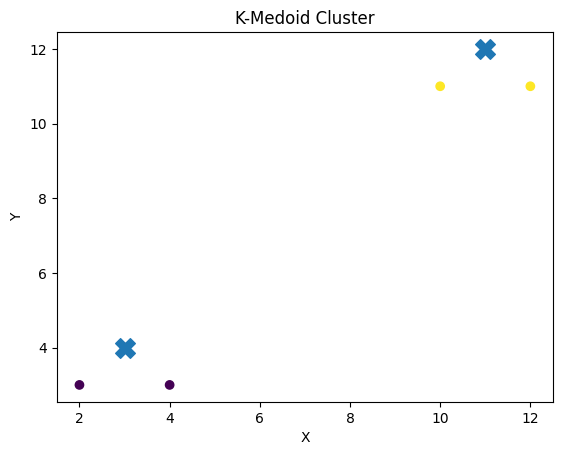

In [11]:
plt.scatter(X[:, 0], X[:, 1], c=labels)
medoids=X[medoid_indices]
plt.scatter(medoids[:, 0], medoids[:, 1],marker='X',s=200)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("K-Medoid Cluster")
plt.show()